## Step 1: Load the Data

**Goal:** Load the raw Telco Customer Churn dataset into a pandas DataFrame.

**Why it matters:** Every project starts with the raw data. We load it exactly as it is, without changing anything yet, so we can inspect its problems in the next step.

**Dataset:** Telco Customer Churn (Already given), 7,043 customers and 21 columns.

In [1]:
# Import the libraries we need for loading and inspecting data
import pandas as pd
import numpy as np

# Load the CSV file into a DataFrame
# Note: the file must be uploaded to Colab and renamed to telco_churn.csv
df = pd.read_csv("telco_churn.csv")

# Show the first 5 rows to confirm the data loaded correctly
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Step 2: First Look

**Goal:** Check the shape, data types, missing values and duplicates of the dataset.

**Why it matters:** We need to find problems in the data before they break our model. For example, a numeric column stored as text will cause errors later.

**What we check:**
- Shape (number of rows and columns)
- Data types of each column
- Duplicate rows
- Missing values
- Class balance of the target column `Churn`

In [2]:
# 1. Shape of the dataset (rows, columns)
print("Shape:", df.shape)

# 2. Column names, data types and non-null counts
print("\nDataset info:")
df.info()

# 3. Count of fully duplicated rows
print("\nDuplicate rows:", df.duplicated().sum())

# 4. Count of missing values (NaN) in each column
print("\nMissing values per column:")
print(df.isnull().sum())

# 5. Class balance of the target column
print("\nChurn distribution (%):")
print((df["Churn"].value_counts(normalize=True) * 100).round(1))

# 6. Hidden problem check: TotalCharges is stored as text (object), so blanks are not counted as NaN
blank_count = (df["TotalCharges"].str.strip() == "").sum()
print("\nBlank values in TotalCharges:", blank_count)

Shape: (7043, 21)

Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  Paperless

## Step 3: Clean the Data

**Goal:** Fix the `TotalCharges` column, drop `customerID`, and convert the target `Churn` to 0/1.

**Why it matters:** Models need clean, numeric data. `TotalCharges` is stored as text and contains 11 blank values, `customerID` is just a unique label with no predictive value, and `Churn` must be numeric for the model.

**What we do:**
- Convert `TotalCharges` from text to numbers (blanks become NaN)
- Inspect the 11 problem rows and fill them sensibly
- Drop `customerID`
- Convert `Churn` from Yes/No to 1/0

In [3]:
# 1. Convert TotalCharges from text to numbers
# errors="coerce" turns the blank strings into NaN instead of raising an error
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# 2. Inspect the rows that became NaN to understand why they are blank
print("NaN count in TotalCharges:", df["TotalCharges"].isnull().sum())
print(df[df["TotalCharges"].isnull()][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

# 3. Fill the NaN values with 0
# These customers have tenure = 0 (brand new), so they have not been billed yet
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# 4. Drop customerID because it is only a unique label and has no predictive value
df = df.drop(columns=["customerID"])

# 5. Convert the target column from Yes/No to 1/0
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

# 6. Verify the cleaning worked
print("\nShape after cleaning:", df.shape)
print("TotalCharges dtype:", df["TotalCharges"].dtype)
print("Total missing values:", df.isnull().sum().sum())
print("Churn values:", df["Churn"].unique())

NaN count in TotalCharges: 11
      customerID  tenure  MonthlyCharges  TotalCharges Churn
488   4472-LVYGI       0           52.55           NaN    No
753   3115-CZMZD       0           20.25           NaN    No
936   5709-LVOEQ       0           80.85           NaN    No
1082  4367-NUYAO       0           25.75           NaN    No
1340  1371-DWPAZ       0           56.05           NaN    No
3331  7644-OMVMY       0           19.85           NaN    No
3826  3213-VVOLG       0           25.35           NaN    No
4380  2520-SGTTA       0           20.00           NaN    No
5218  2923-ARZLG       0           19.70           NaN    No
6670  4075-WKNIU       0           73.35           NaN    No
6754  2775-SEFEE       0           61.90           NaN    No

Shape after cleaning: (7043, 20)
TotalCharges dtype: float64
Total missing values: 0
Churn values: [0 1]


## Step 4: Exploratory Data Analysis (The Story of Why Customers Leave)

**Goal:** Understand *why* customers leave, in plain language anyone can follow.

**How to read the charts:** Every bar shows the percentage of customers who left. A **red bar** means that group leaves *more* than the company average. A **grey bar** means it leaves *less*. The dashed line is the company average.

**The story in 5 chapters:**
1. The big picture: how many customers leave?
2. Does the type of contract matter?
3. Are new customers more likely to leave?
4. Does a higher bill push people away?
5. Does the payment method matter?
6. The riskiest customer: putting it all together

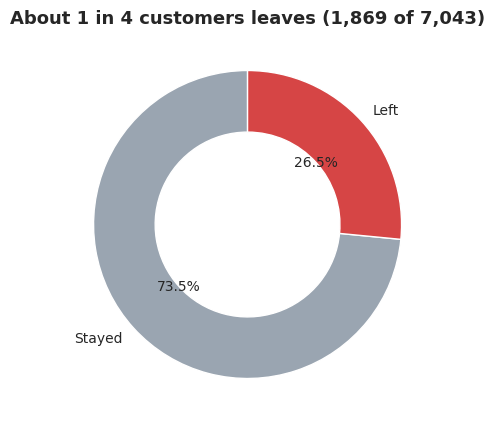

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams.update({"axes.titlesize": 13, "axes.titleweight": "bold"})

RED, GREY = "#D64545", "#9AA5B1"
avg = df["Churn"].mean() * 100   # company-wide churn rate (%)

def rate_chart(rates, title, xlabel, rotation=0):
    # Bar chart of churn rate per group; bars above the company average are red
    colors = [RED if r > avg else GREY for r in rates.values]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.bar(rates.index.astype(str), rates.values, color=colors)
    ax.bar_label(bars, fmt="%.1f%%", fontsize=11)
    ax.axhline(avg, color="black", linestyle="--", linewidth=1)
    ax.text(len(rates) - 0.5, avg + 1, f"Company average {avg:.1f}%", ha="right", fontsize=10)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Customers who left (%)")
    ax.set_ylim(0, rates.max() + 12)
    plt.setp(ax.get_xticklabels(), rotation=rotation, ha="right" if rotation else "center")
    plt.tight_layout()
    plt.show()

# Chapter 1: the big picture
left = int(df["Churn"].sum())
total = len(df)
fig, ax = plt.subplots(figsize=(5, 5))
ax.pie([total - left, left], labels=["Stayed", "Left"], colors=[GREY, RED],
       autopct="%1.1f%%", startangle=90, wedgeprops={"width": 0.4})
ax.set_title(f"About 1 in 4 customers leaves ({left:,} of {total:,})")
plt.show()

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn, dtype: float64


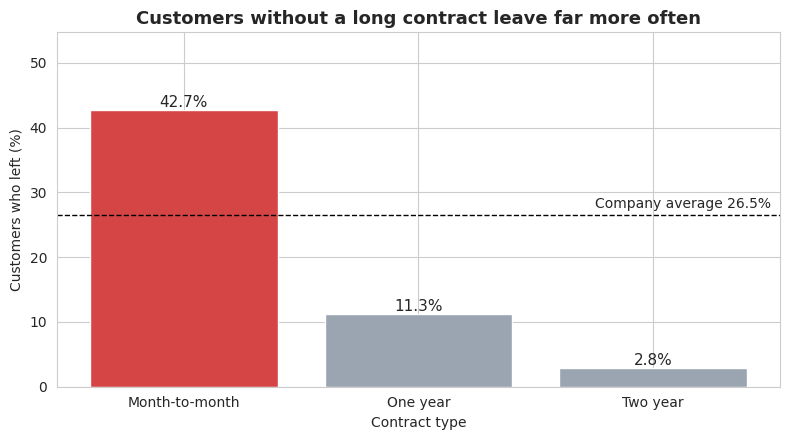

In [6]:
# Chapter 2: churn rate by contract type
contract_rate = df.groupby("Contract")["Churn"].mean() * 100
print(contract_rate.round(1))

rate_chart(contract_rate,
           "Customers without a long contract leave far more often",
           "Contract type")

TenureGroup
0-12 months     47.4
13-24 months    28.7
25-48 months    20.4
49-72 months     9.5
Name: Churn, dtype: float64


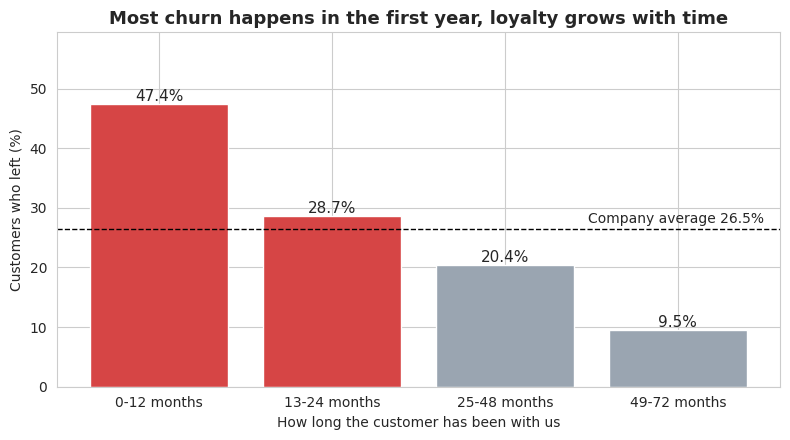

In [7]:
# Chapter 3: churn rate by how long the customer has been with us
df["TenureGroup"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                           labels=["0-12 months", "13-24 months", "25-48 months", "49-72 months"])
tenure_rate = df.groupby("TenureGroup", observed=True)["Churn"].mean() * 100
print(tenure_rate.round(1))

rate_chart(tenure_rate,
           "Most churn happens in the first year, loyalty grows with time",
           "How long the customer has been with us")

BillGroup
Under 35    10.9
35-70       23.9
70-90       37.8
Over 90     32.8
Name: Churn, dtype: float64


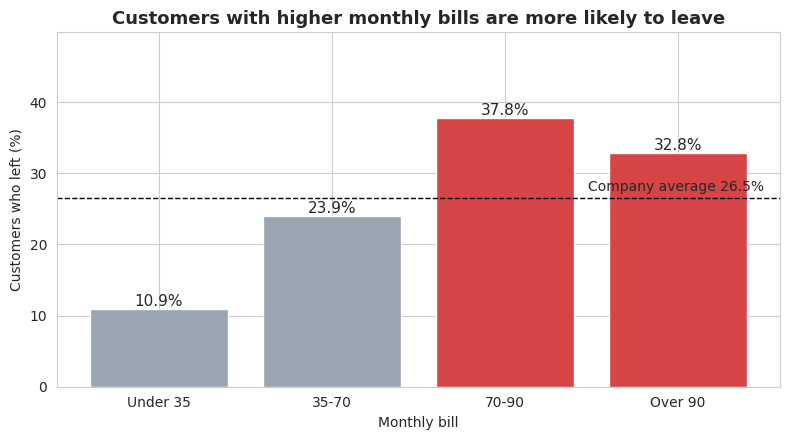

PaymentMethod
Credit card (automatic)      15.2
Bank transfer (automatic)    16.7
Mailed check                 19.1
Electronic check             45.3
Name: Churn, dtype: float64


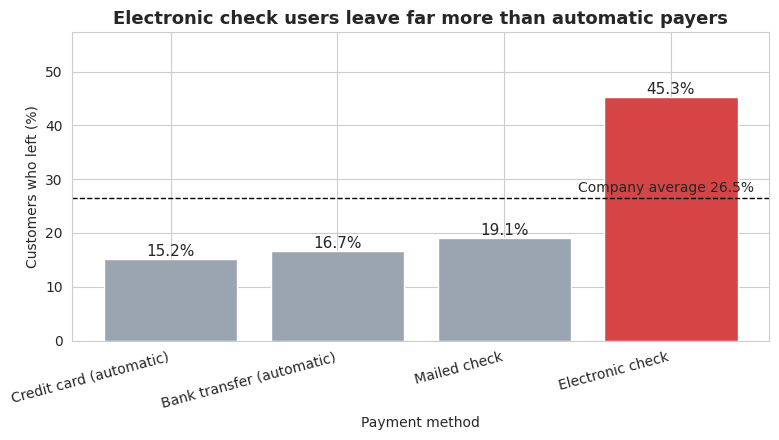

In [8]:
# Chapter 4: churn rate by monthly bill
df["BillGroup"] = pd.cut(df["MonthlyCharges"], bins=[0, 35, 70, 90, 200],
                         labels=["Under 35", "35-70", "70-90", "Over 90"])
bill_rate = df.groupby("BillGroup", observed=True)["Churn"].mean() * 100
print(bill_rate.round(1))

rate_chart(bill_rate,
           "Customers with higher monthly bills are more likely to leave",
           "Monthly bill")

# Chapter 5: churn rate by payment method
payment_rate = df.groupby("PaymentMethod")["Churn"].mean().sort_values() * 100
print(payment_rate.round(1))

rate_chart(payment_rate,
           "Electronic check users leave far more than automatic payers",
           "Payment method", rotation=15)

Customers in high-risk profile: 954
High-risk profile    63.1
Everyone else        20.8
dtype: float64


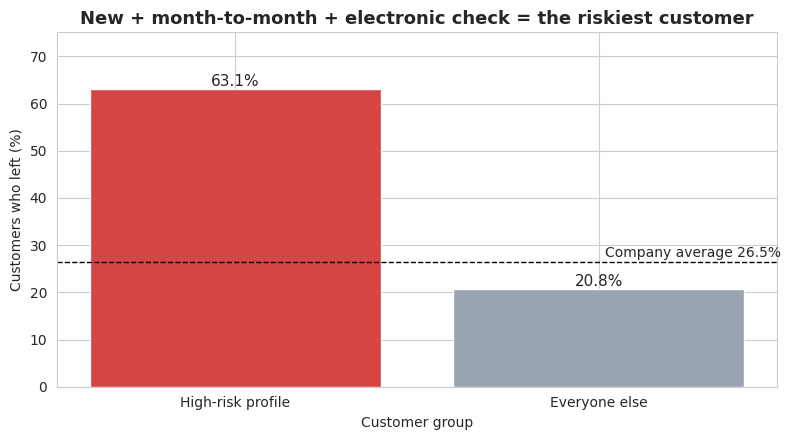

In [9]:
# Chapter 6: combine the three biggest warning signs into one "high-risk" profile
high_risk = (
    (df["Contract"] == "Month-to-month")
    & (df["tenure"] <= 12)
    & (df["PaymentMethod"] == "Electronic check")
)

profile_rate = pd.Series({
    "High-risk profile": df[high_risk]["Churn"].mean() * 100,
    "Everyone else": df[~high_risk]["Churn"].mean() * 100,
})
print("Customers in high-risk profile:", high_risk.sum())
print(profile_rate.round(1))

rate_chart(profile_rate,
           "New + month-to-month + electronic check = the riskiest customer",
           "Customer group")

## Step 5: Prepare (Train/Test Split)

**Goal:** Separate the features (`X`) from the target (`y`), then split the data 80% for training and 20% for testing.

**Why it matters:** The test set acts as "unseen customers" so we can honestly check how well the model works. Only 26.5% of customers churn, so we use `stratify=y` to keep that same ratio in both the training and test sets. Without it, the test set could end up with too few churners and give a misleading score.

**Important:** We split *before* scaling or encoding, so no information from the test set leaks into training.

In [11]:
# Remove the helper columns that were created only for EDA plots
df = df.drop(columns=["TenureGroup", "BillGroup"], errors="ignore")
print("Shape of df:", df.shape)   # should be (7043, 20)

# Redo the split with the clean data
X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("X shape:", X.shape)        # should be (7043, 19)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("\nChurn rate (%):")
print("Full data :", round(y.mean() * 100, 1))
print("Train set :", round(y_train.mean() * 100, 1))
print("Test set  :", round(y_test.mean() * 100, 1))
print("\nColumns:", list(X.columns))

Shape of df: (7043, 20)
X shape: (7043, 19)
X_train: (5634, 19) | X_test: (1409, 19)

Churn rate (%):
Full data : 26.5
Train set : 26.5
Test set  : 26.5

Columns: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


## Step 6: Preprocessing Pipeline

**Goal:** Build one reusable preprocessor that scales the numeric columns and one-hot encodes the categorical columns.

**Why it matters:** Models only understand numbers. Putting all the steps in one object guarantees that training data, test data and the live app inputs are transformed in exactly the same way.

**What we do:**
- **Numeric columns** (`tenure`, `MonthlyCharges`, `TotalCharges`): `StandardScaler`, so they all sit on a similar scale
- **Categorical columns** (Yes/No, contract type, etc.): `OneHotEncoder`, which turns each category into its own 0/1 column
- **`SeniorCitizen`** is already 0/1, so it passes through unchanged

**Important:** We `fit` on the training data only, then `transform` the test data. This prevents data leakage. `handle_unknown="ignore"` stops the app from crashing if it ever sees a category it did not see in training.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numeric columns that need scaling
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

# Categorical columns that need one-hot encoding (all text columns)
cat_cols = X.select_dtypes(include=["object", "string"]).columns.tolist()

print("Numeric columns    :", num_cols)
print("Categorical columns:", len(cat_cols))

# Combine both transformations into one preprocessor
# remainder="passthrough" keeps SeniorCitizen (already 0/1) unchanged
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ],
    remainder="passthrough",
)

# Fit on TRAIN only, then apply the same transformation to TEST
X_train_t = preprocessor.fit_transform(X_train)
X_test_t = preprocessor.transform(X_test)

# Verify the result
print("\nTransformed train shape:", X_train_t.shape)
print("Transformed test shape :", X_test_t.shape)

# Scaled numeric columns should have mean ~0 and std ~1 on the train set
print("\nMean of scaled numeric columns:", X_train_t[:, :3].mean(axis=0).round(3))
print("Std of scaled numeric columns :", X_train_t[:, :3].std(axis=0).round(3))

Numeric columns    : ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical columns: 15

Transformed train shape: (5634, 45)
Transformed test shape : (1409, 45)

Mean of scaled numeric columns: [-0. -0. -0.]
Std of scaled numeric columns : [1. 1. 1.]


## Step 7: Compare Models

**Goal:** Train three different algorithms on the same data and see which one suits this problem best.

**Why it matters:** No single algorithm wins every time. Comparing them on the same train/test split is a fair way to choose.

**Models:**
- **Logistic Regression:** a simple, fast baseline that draws a straight dividing line between churners and non-churners
- **Decision Tree:** asks a chain of yes/no questions (for example "is the contract month-to-month?")
- **Random Forest:** many decision trees voting together

**Metrics (for the churn class):**
- **Accuracy:** overall % of correct predictions
- **Precision:** of customers we flagged as churners, how many really left
- **Recall:** of customers who really left, how many we caught
- **F1:** the balance between precision and recall

Each model is wrapped in a `Pipeline` together with the preprocessor from Step 6, so scaling and encoding are applied automatically.

In [13]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# The three models we want to compare
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
}

results = []
for name, model in models.items():
    # Pipeline = preprocessor + model, so all steps run together
    pipe = Pipeline([("preprocessor", preprocessor), ("model", model)])

    # Train on the training set, then predict on the unseen test set
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
    })

# Show all results in one table
results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df

,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,0.806,0.657,0.559,0.604
Decision Tree,0.728,0.488,0.500,0.494
Random Forest,0.786,0.623,0.487,0.547


## Step 8: Focus on Recall (class_weight="balanced")

**Goal:** Make the models pay more attention to churners, and compare recall before and after.

**Why it matters:** Only 26.5% of customers churn, so a model can score well by mostly predicting "stays". But a missed churner is a lost customer, so catching churners (recall) matters most.

**What `class_weight="balanced"` does:** It tells the model that a mistake on a churner is more costly than a mistake on a non-churner (roughly 2.8x, because churners are about 2.8 times rarer). The model is then forced to take the minority class seriously.

**What we compare:** Recall of each model with default settings (Step 7) versus balanced.

Balanced models:


,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,0.738,0.504,0.783,0.614
Decision Tree,0.736,0.503,0.481,0.492
Random Forest,0.778,0.607,0.463,0.525



Recall comparison:


,Recall (default),Recall (balanced),Change
Model,,,
Logistic Regression,0.559,0.783,0.224
Decision Tree,0.500,0.481,-0.019
Random Forest,0.487,0.463,-0.024


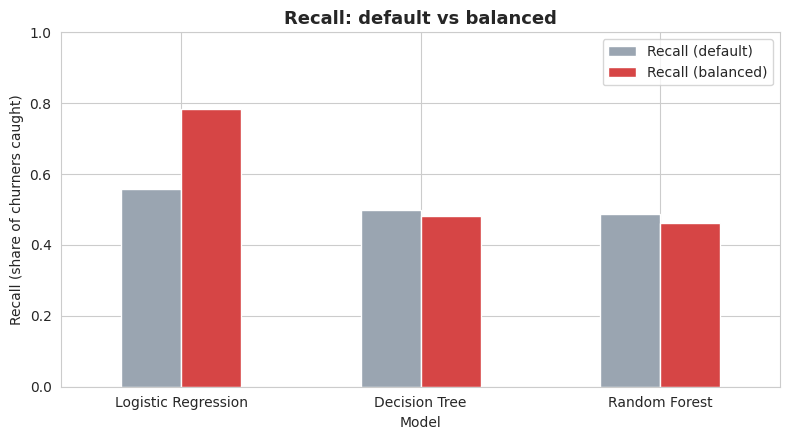

Best model by recall: Logistic Regression


In [14]:
# Same three models, now with class_weight="balanced"
balanced_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(random_state=42, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(random_state=42, class_weight="balanced"),
}

balanced_results = []
for name, model in balanced_models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    balanced_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
    })

balanced_df = pd.DataFrame(balanced_results).set_index("Model").round(3)
print("Balanced models:")
display(balanced_df)

# Recall before (default, from Step 7) vs after (balanced)
recall_compare = pd.DataFrame({
    "Recall (default)": results_df["Recall"],
    "Recall (balanced)": balanced_df["Recall"],
})
recall_compare["Change"] = (recall_compare["Recall (balanced)"] - recall_compare["Recall (default)"]).round(3)
print("\nRecall comparison:")
display(recall_compare)

# Plot the comparison
recall_compare[["Recall (default)", "Recall (balanced)"]].plot(
    kind="bar", figsize=(8, 4.5), color=["#9AA5B1", "#D64545"], rot=0
)
plt.title("Recall: default vs balanced")
plt.ylabel("Recall (share of churners caught)")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

# Best model by recall
print("Best model by recall:", balanced_df["Recall"].idxmax())

In [15]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Calculate the balanced weights for the train set
weights = compute_class_weight(class_weight="balanced", classes=np.array([0, 1]), y=y_train)
print("Weight for Stay (0) :", round(weights[0], 2))
print("Weight for Churn (1):", round(weights[1], 2))

Weight for Stay (0) : 0.68
Weight for Churn (1): 1.88


## Step 9: Hyperparameter Tuning (GridSearchCV)

**Goal:** Tune the best model from Step 8 (Logistic Regression) to squeeze out extra performance.

**Why it matters:** Default settings are rarely the best settings. GridSearchCV tries every combination from a grid of settings and picks the best one.

**How it works:**
- It tests each combination using 5-fold cross-validation **inside the training set only**, so the test set stays untouched for the final evaluation in Step 10.
- We score by **recall**, because catching churners is our main goal.

**Settings we tune:**
- `C`: the regularization strength (smaller C = simpler, more cautious model)
- `solver`: the algorithm used to fit the model

In [16]:
from sklearn.model_selection import GridSearchCV

# Pipeline with the best model from Step 8 (balanced Logistic Regression)
lr_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

# Settings to try (model__ prefix = a setting of the "model" step in the pipeline)
param_grid = {
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "model__solver": ["lbfgs", "liblinear"],
}

# 5-fold cross-validation on the TRAIN set only, scored by recall
grid = GridSearchCV(lr_pipe, param_grid, cv=5, scoring="recall", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best settings :", grid.best_params_)
print("Best CV recall:", round(grid.best_score_, 3))

# Check the tuned model on the unseen test set
tuned_model = grid.best_estimator_
y_pred_tuned = tuned_model.predict(X_test)

tuned_row = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred_tuned),
    "Precision": precision_score(y_test, y_pred_tuned),
    "Recall": recall_score(y_test, y_pred_tuned),
    "F1": f1_score(y_test, y_pred_tuned),
}).round(3)

# Before (Step 8) vs after tuning
compare_tuning = pd.DataFrame({
    "Before tuning": balanced_df.loc["Logistic Regression"],
    "After tuning": tuned_row,
})
compare_tuning

Best settings : {'model__C': 0.001, 'model__solver': 'liblinear'}
Best CV recall: 0.809


,Before tuning,After tuning
Accuracy,0.738,0.722
Precision,0.504,0.486
Recall,0.783,0.807
F1,0.614,0.606


## Step 10: Evaluate on Unseen Data

**Goal:** Check how the final tuned model performs on the test set, which it has never seen.

**Why it matters:** This is the honest proof that the model works on new customers, not just the ones it trained on.

**What we use:**
- **Confusion matrix:** a 2x2 table showing exactly where the model is right and wrong
  - True Negative: predicted stay, really stayed
  - False Positive: predicted churn, but the customer stayed (a false alarm)
  - False Negative: predicted stay, but the customer left (a missed churner, the costly mistake)
  - True Positive: predicted churn, and the customer left (a churner we caught)
- **Classification report:** precision, recall and F1 for each class

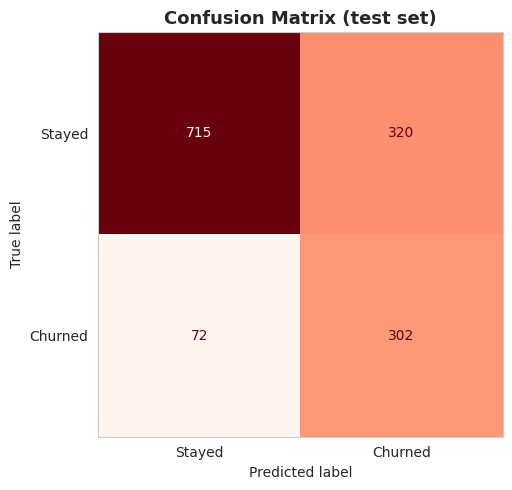

              precision    recall  f1-score   support

      Stayed      0.909     0.691     0.785      1035
     Churned      0.486     0.807     0.606       374

    accuracy                          0.722      1409
   macro avg      0.697     0.749     0.696      1409
weighted avg      0.796     0.722     0.737      1409

Real churners in the test set : 374
Churners we caught            : 302  (80.7%)
Churners we missed            : 72
False alarms (stayed, flagged): 320


In [17]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# Predictions of the final tuned model on the unseen test set
y_pred_final = tuned_model.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_final)
disp = ConfusionMatrixDisplay(cm, display_labels=["Stayed", "Churned"])
fig, ax = plt.subplots(figsize=(5.5, 5))
disp.plot(ax=ax, cmap="Reds", colorbar=False)
ax.set_title("Confusion Matrix (test set)")
ax.grid(False)
plt.tight_layout()
plt.show()

# Classification report
print(classification_report(y_test, y_pred_final, target_names=["Stayed", "Churned"], digits=3))

# Plain-language summary of the confusion matrix
tn, fp, fn, tp = cm.ravel()
print(f"Real churners in the test set : {tp + fn}")
print(f"Churners we caught            : {tp}  ({tp / (tp + fn):.1%})")
print(f"Churners we missed            : {fn}")
print(f"False alarms (stayed, flagged): {fp}")

## Step 11: Business Recommendations

Based on our analysis and model, here are four actions the company can take to reduce churn.

### 1. Move month-to-month customers onto longer contracts
Month-to-month customers churn at **42.7%**, compared with **11.3%** on one-year and **2.8%** on two-year contracts. Offer a small discount or a free service upgrade to customers who switch to a one-year or two-year plan.

### 2. Focus on the first year with a strong onboarding program
Customers in their first 12 months churn at **47.4%**, and the rate falls steadily after that. Contact new customers early (a welcome call, a check-in after 1 to 3 months) to fix problems before they leave.

### 3. Nudge electronic check users toward automatic payments
Electronic check users churn at **45.3%**, versus roughly **15% to 19%** for all other payment methods. Offer a small incentive (for example a bill credit) for switching to bank transfer or credit card auto-pay.

### 4. Use the model to find and protect high-risk customers every month
Our final model catches **80.7%** of customers who are about to leave (302 of 374 in the test set). Run it on the current customer base each month and send retention offers to the customers it flags as high risk. The trade-off is 320 false alarms in the test set, but a retention offer to a customer who would have stayed anyway costs far less than losing a customer who leaves.

**Highest-priority group:** new customers on month-to-month contracts who pay by electronic check. In our data, this group churns at **63.1%** (954 customers), versus 20.8% for everyone else.

*Note: these patterns show association, not proof of cause. Before rolling out any offer company-wide, test it on a small group and measure whether churn really drops.*

## Step 12: Predict a Single Customer (Dummy Data)

**Goal:** Give the final model one customer as a Python dictionary and see whether it predicts churn.

**Why it matters:** This is exactly what the live app will do: take a customer's details, turn them into a one-row table, and ask the model for a churn probability. If it works here, it will work in the app.

**Key rules:**
- The dictionary must contain **all 19 feature columns**, with the same names and the same spelling of values as the training data.
- We pass the raw values. The pipeline does the scaling and one-hot encoding by itself.
- `predict_proba` gives the churn probability, which we convert into a High / Medium / Low risk level.

In [18]:
# Helper: convert a churn probability into a business-friendly risk level
def risk_level(prob):
    if prob >= 0.70:
        return "High"
    elif prob >= 0.40:
        return "Medium"
    return "Low"

# Dummy customer 1: new, month-to-month, electronic check, fiber optic (a risky profile)
customer_1 = {
    "gender": "Female", "SeniorCitizen": 0, "Partner": "No", "Dependents": "No",
    "tenure": 2, "PhoneService": "Yes", "MultipleLines": "No",
    "InternetService": "Fiber optic", "OnlineSecurity": "No", "OnlineBackup": "No",
    "DeviceProtection": "No", "TechSupport": "No", "StreamingTV": "No",
    "StreamingMovies": "No", "Contract": "Month-to-month", "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check", "MonthlyCharges": 85.5, "TotalCharges": 171.0,
}

# Dummy customer 2: long-term, two-year contract, auto-pay, has support services (a safe profile)
customer_2 = {
    "gender": "Male", "SeniorCitizen": 0, "Partner": "Yes", "Dependents": "Yes",
    "tenure": 60, "PhoneService": "Yes", "MultipleLines": "Yes",
    "InternetService": "DSL", "OnlineSecurity": "Yes", "OnlineBackup": "Yes",
    "DeviceProtection": "Yes", "TechSupport": "Yes", "StreamingTV": "No",
    "StreamingMovies": "No", "Contract": "Two year", "PaperlessBilling": "No",
    "PaymentMethod": "Bank transfer (automatic)", "MonthlyCharges": 55.0, "TotalCharges": 3300.0,
}

def predict_customer(customer_dict, model):
    # Dictionary -> one-row DataFrame, with columns in the same order as training
    row = pd.DataFrame([customer_dict])[list(X.columns)]
    prob = model.predict_proba(row)[0, 1]          # probability of churn (class 1)
    pred = model.predict(row)[0]                   # 1 = churn, 0 = stay
    return prob, pred

for name, cust in [("Customer 1", customer_1), ("Customer 2", customer_2)]:
    prob, pred = predict_customer(cust, tuned_model)
    print(f"{name}: churn probability = {prob:.1%} | risk = {risk_level(prob)} | "
          f"prediction = {'WILL CHURN' if pred == 1 else 'WILL STAY'}")

Customer 1: churn probability = 79.3% | risk = High | prediction = WILL CHURN
Customer 2: churn probability = 16.2% | risk = Low | prediction = WILL STAY


## Step 13: Save the Model with joblib

**Goal:** Save the final tuned pipeline to a single file so the Streamlit app can load it instantly, without retraining.

**Why it matters:** Training happens once in the notebook, but the app needs the trained model every time it runs. We save the **whole pipeline** (preprocessor + model), not just the model, so scaling and one-hot encoding travel with it.

**Important:** A saved model file depends on the library version it was created with. We record the scikit-learn version, because the app must use the same version to load the file safely.

In [19]:
import joblib
import os
import sklearn

# Save the whole tuned pipeline (preprocessor + Logistic Regression) to one file
MODEL_PATH = "churn_model.joblib"
joblib.dump(tuned_model, MODEL_PATH)

# Confirm that the file was created and check its size
size_kb = os.path.getsize(MODEL_PATH) / 1024
print(f"Saved: {MODEL_PATH} ({size_kb:.1f} KB)")

# Record the scikit-learn version used to train the model (needed for requirements.txt)
print("scikit-learn version:", sklearn.__version__)

Saved: churn_model.joblib (7.9 KB)
scikit-learn version: 1.6.1


## Step 14: Verify the Saved Model

**Goal:** Load the saved file back and prove it is identical to the original model.

**Why it matters:** The app will use the loaded file, not the model in this notebook. If saving or loading changed anything, the app would give different predictions from the ones we evaluated. We check this four ways:
1. Same predictions on the whole test set
2. Same churn probabilities
3. Same learned weights and settings
4. Same result for our dummy customers

In [20]:
import numpy as np

# Load the saved pipeline from disk
loaded_model = joblib.load(MODEL_PATH)

# Check 1: predictions on the full test set
pred_orig = tuned_model.predict(X_test)
pred_loaded = loaded_model.predict(X_test)
print("1. Same predictions         :", np.array_equal(pred_orig, pred_loaded))

# Check 2: churn probabilities on the full test set
proba_orig = tuned_model.predict_proba(X_test)[:, 1]
proba_loaded = loaded_model.predict_proba(X_test)[:, 1]
print("2. Same probabilities       :", np.allclose(proba_orig, proba_loaded))
print("   Max probability difference:", np.abs(proba_orig - proba_loaded).max())

# Check 3: learned weights and settings inside the Logistic Regression step
lr_orig = tuned_model.named_steps["model"]
lr_loaded = loaded_model.named_steps["model"]
print("3. Same coefficients        :", np.array_equal(lr_orig.coef_, lr_loaded.coef_))
print("   Same settings (C, solver):", lr_orig.C == lr_loaded.C and lr_orig.solver == lr_loaded.solver)

# Check 4: our dummy customers give the same result
for name, cust in [("Customer 1", customer_1), ("Customer 2", customer_2)]:
    p_orig, _ = predict_customer(cust, tuned_model)
    p_loaded, _ = predict_customer(cust, loaded_model)
    print(f"4. {name}: original {p_orig:.1%} | loaded {p_loaded:.1%}")

# Final score of the loaded model on the test set
print("\nRecall of loaded model:", round(recall_score(y_test, pred_loaded), 3))

# Same content, but they are two separate objects in memory
print("Same object in memory?     :", loaded_model is tuned_model)

1. Same predictions         : True
2. Same probabilities       : True
   Max probability difference: 0.0
3. Same coefficients        : True
   Same settings (C, solver): True
4. Customer 1: original 79.3% | loaded 79.3%
4. Customer 2: original 16.2% | loaded 16.2%

Recall of loaded model: 0.807
Same object in memory?     : False


## Step 15: Input Schema Validation

**Goal:** Reject bad customer data before it reaches the model, with clear error messages.

**Why it matters:** The pipeline ignores unknown categories silently, so a typo like "Monthly" instead of "Month-to-month" would produce a wrong prediction without any warning. Validation protects the app from typos, missing fields and impossible values.

**What we check:**
1. All 19 fields present, and no unexpected fields
2. Categorical fields use one of the known values (exact spelling)
3. Numeric fields are real numbers inside sensible limits (errors), and a warning if they fall outside the training range
4. Fields agree with each other (for example, no internet add-ons if the customer has no internet)

**How:** The schema is built from the training data and saved to `churn_schema.json`. The checking logic lives in `validation.py`, so the notebook and the Streamlit app share exactly the same rules.

In [21]:
import json

# Helper: allowed limits (errors) and the range seen in training (warnings)
def numeric_rule(col, hard_min, hard_max):
    return {
        "hard_min": hard_min, "hard_max": hard_max,
        "train_min": float(X_train[col].min()), "train_max": float(X_train[col].max()),
    }

schema = {
    # Column order exactly as used for training
    "features": list(X.columns),
    # Allowed values for every text column, taken from the training data
    "categorical": {c: sorted(X_train[c].unique().tolist()) for c in cat_cols},
    # Numeric columns (hard limits are realistic business limits chosen by us)
    "numeric": {
        "SeniorCitizen": {},
        "tenure": numeric_rule("tenure", 0, 120),
        "MonthlyCharges": numeric_rule("MonthlyCharges", 0, 300),
        "TotalCharges": numeric_rule("TotalCharges", 0, 50000),
    },
}

with open("churn_schema.json", "w") as f:
    json.dump(schema, f, indent=2)

print("Saved churn_schema.json")
print("Features:", len(schema["features"]))
print("Contract values:", schema["categorical"]["Contract"])
print("Numeric rules:", json.dumps(schema["numeric"]["tenure"]))

Saved churn_schema.json
Features: 19
Contract values: ['Month-to-month', 'One year', 'Two year']
Numeric rules: {"hard_min": 0, "hard_max": 120, "train_min": 0.0, "train_max": 72.0}


In [22]:
%%writefile validation.py
import json
import math
import numbers

# Load the schema that was built from the training data
with open("churn_schema.json") as f:
    SCHEMA = json.load(f)

INTERNET_COLS = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                 "TechSupport", "StreamingTV", "StreamingMovies"]


class ChurnInputError(ValueError):
    """Raised when a customer record does not match the expected schema."""


def _is_number(v):
    # True for real, finite numbers (int/float/numpy numbers), but not for bool
    return isinstance(v, numbers.Real) and not isinstance(v, bool) and math.isfinite(v)


def validate_customer(data):
    """Validate one customer dictionary.

    Returns (clean_record, warnings). Raises ChurnInputError listing ALL problems found.
    """
    if not isinstance(data, dict):
        raise ChurnInputError("Input must be a dictionary of customer fields.")

    errors, warnings, clean = [], [], {}
    features = SCHEMA["features"]

    # 1. Missing and unexpected fields
    missing = [f for f in features if f not in data]
    extra = [k for k in data if k not in features]
    if missing:
        errors.append(f"Missing fields: {missing}")
    if extra:
        errors.append(f"Unexpected fields: {extra}")

    # 2. Categorical fields must use one of the known values (exact spelling)
    for col, allowed in SCHEMA["categorical"].items():
        if col in data:
            value = data[col].strip() if isinstance(data[col], str) else data[col]
            if value in allowed:
                clean[col] = value
            else:
                errors.append(f"{col}: {data[col]!r} is not valid. Allowed values: {allowed}")

    # 3. Numeric fields must be real numbers inside sensible limits
    for col, rule in SCHEMA["numeric"].items():
        if col not in data:
            continue
        value = data[col]
        if not _is_number(value):
            errors.append(f"{col}: must be a finite number, got {value!r}")
            continue
        if col == "SeniorCitizen":
            if value in (0, 1):
                clean[col] = int(value)
            else:
                errors.append(f"SeniorCitizen: must be 0 or 1, got {value!r}")
            continue
        if col == "tenure" and value != int(value):
            errors.append(f"tenure: must be a whole number of months, got {value!r}")
            continue
        if value < rule["hard_min"] or value > rule["hard_max"]:
            errors.append(f"{col}: {value} is outside the allowed range "
                          f"[{rule['hard_min']}, {rule['hard_max']}]")
            continue
        if value < rule["train_min"] or value > rule["train_max"]:
            warnings.append(f"{col}: {value} is outside the range seen in training "
                            f"[{rule['train_min']}, {rule['train_max']}], so the prediction may be less reliable.")
        clean[col] = int(value) if col == "tenure" else float(value)

    # 4. Cross-field consistency (only when the fields involved are valid)
    phone, lines = clean.get("PhoneService"), clean.get("MultipleLines")
    if phone == "No" and lines is not None and lines != "No phone service":
        errors.append("MultipleLines must be 'No phone service' when PhoneService is 'No'.")
    if phone == "Yes" and lines == "No phone service":
        errors.append("MultipleLines cannot be 'No phone service' when PhoneService is 'Yes'.")

    internet = clean.get("InternetService")
    for col in INTERNET_COLS:
        v = clean.get(col)
        if internet == "No" and v is not None and v != "No internet service":
            errors.append(f"{col} must be 'No internet service' when InternetService is 'No'.")
        if internet in ("DSL", "Fiber optic") and v == "No internet service":
            errors.append(f"{col} cannot be 'No internet service' when the customer has internet.")

    if errors:
        raise ChurnInputError("\n".join(f"- {e}" for e in errors))

    # Return the record in the exact column order used for training
    return {f: clean[f] for f in features}, warnings

Writing validation.py


In [23]:
import importlib
import validation
importlib.reload(validation)
from validation import validate_customer, ChurnInputError

def safe_predict(customer_dict, model):
    # Validate first, then predict only if the data is clean
    clean, warns = validate_customer(customer_dict)
    prob, _ = predict_customer(clean, model)
    return prob, warns

# Build test cases from customer_1 by breaking one thing at a time
def changed(**kwargs):
    c = dict(customer_1)
    c.update(kwargs)
    return c

missing_tenure = dict(customer_1)
del missing_tenure["tenure"]

cases = {
    "Valid customer": customer_1,
    "Typo in Contract": changed(Contract="Monthly"),
    "Missing field (tenure)": missing_tenure,
    "Negative tenure": changed(tenure=-5),
    "Number sent as text": changed(MonthlyCharges="85.5"),
    "Extra field": changed(favourite_color="red"),
    "No phone, but has multiple lines": changed(PhoneService="No"),
    "No internet, but has add-ons": changed(InternetService="No"),
    "Valid but unusual tenure (80)": changed(tenure=80),
}

for name, cust in cases.items():
    print(f"\n--- {name}")
    try:
        prob, warns = safe_predict(cust, loaded_model)
        print(f"ACCEPTED, churn probability = {prob:.1%}")
        for w in warns:
            print("WARNING:", w)
    except ChurnInputError as e:
        print("REJECTED:")
        print(e)

# Sanity check: real customers from the dataset must all pass
failed = 0
for row in X.to_dict("records"):
    try:
        validate_customer(row)
    except ChurnInputError:
        failed += 1
print("\nRows from the real dataset rejected by validation:", failed)


--- Valid customer
ACCEPTED, churn probability = 79.3%

--- Typo in Contract
REJECTED:
- Contract: 'Monthly' is not valid. Allowed values: ['Month-to-month', 'One year', 'Two year']

--- Missing field (tenure)
REJECTED:
- Missing fields: ['tenure']

--- Negative tenure
REJECTED:
- tenure: -5 is outside the allowed range [0, 120]

--- Number sent as text
REJECTED:
- MonthlyCharges: must be a finite number, got '85.5'

--- Extra field
REJECTED:
- Unexpected fields: ['favourite_color']

--- No phone, but has multiple lines
REJECTED:
- MultipleLines must be 'No phone service' when PhoneService is 'No'.

--- No internet, but has add-ons
REJECTED:
- OnlineSecurity must be 'No internet service' when InternetService is 'No'.
- OnlineBackup must be 'No internet service' when InternetService is 'No'.
- DeviceProtection must be 'No internet service' when InternetService is 'No'.
- TechSupport must be 'No internet service' when InternetService is 'No'.
- StreamingTV must be 'No internet service' 

## Step 16: Model Card

**Goal:** Write a short, honest document describing what the model is, how it was built, how well it works, and where it should not be used.

**Why it matters:** A model card lets anyone (a manager, a recruiter, a future teammate) understand the model without reading the notebook. It also shows we know the model's limits.

**How:** The card is generated from the notebook's own variables, so every number matches our results exactly. It is saved as `MODEL_CARD.md` for the GitHub repo.

In [24]:
import datetime
import sklearn
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# 1. Numbers for the card come straight from the notebook, so nothing is typed by hand
y_final = loaded_model.predict(X_test)
tn, fp, fn, tp = confusion_matrix(y_test, y_final).ravel()
acc = accuracy_score(y_test, y_final)
prec = precision_score(y_test, y_final)
rec = recall_score(y_test, y_final)
f1 = f1_score(y_test, y_final)
stay_recall = tn / (tn + fp)
lr = loaded_model.named_steps["model"]

# 2. Rows of the model comparison table (default models, then balanced models)
def table_rows(df_scores, label):
    return "\n".join(
        f"| {name} ({label}) | {r['Accuracy']:.3f} | {r['Precision']:.3f} | {r['Recall']:.3f} | {r['F1']:.3f} |"
        for name, r in df_scores.iterrows()
    )

comparison_rows = table_rows(results_df, "default") + "\n" + table_rows(balanced_df, "balanced")

# 3. Write the model card
card = f"""# Model Card: Customer Churn Predictor

*Created: {datetime.date.today()} | scikit-learn {sklearn.__version__}*

## Model details
- **Task:** Binary classification, predicting whether a telecom customer will churn (leave).
- **Model:** Logistic Regression (`class_weight="balanced"`, `C={lr.C}`, `solver="{lr.solver}"`) inside a scikit-learn Pipeline.
- **Pipeline:** `StandardScaler` on tenure, MonthlyCharges and TotalCharges, `OneHotEncoder` on the 15 categorical columns, `SeniorCitizen` passed through, then the classifier.
- **Output:** a churn probability, converted to a risk level: Low (below 40%), Medium (40% to 70%), High (70% and above).
- **File:** `churn_model.joblib`. Input rules are in `validation.py` and `churn_schema.json`.

## Intended use
- Help a retention team rank customers by churn risk and decide who gets a retention offer.
- A decision-support tool for a portfolio and learning project, not a fully automated decision-maker.

## Out of scope
- Any decision that affects a customer's price, service or eligibility without human review.
- Other companies, countries or time periods: the model has only seen this one dataset.
- Explaining *why* a single customer will leave. The model finds patterns, not causes.

## Data
- Telco Customer Churn dataset from Kaggle: 7,043 customers, 21 columns, 26.5% churned.
- `customerID` dropped. 11 blank `TotalCharges` values (customers with tenure 0) filled with 0.
- Split 80/20 with `stratify=y` and `random_state=42`: {len(X_train):,} training rows and {len(X_test):,} test rows.

## Training
- Three algorithms compared on the same split, then `class_weight="balanced"` added to handle the 26.5% / 73.5% class imbalance.
- Best model (Logistic Regression) tuned with `GridSearchCV`, 5-fold cross-validation on the training set only, scored by recall.

## Performance (test set, {len(y_test):,} customers, {tp + fn} real churners)

| Metric | Value |
|---|---|
| Recall (churners caught) | {rec:.3f} |
| Precision (flagged customers who really left) | {prec:.3f} |
| F1 | {f1:.3f} |
| Accuracy | {acc:.3f} |
| Recall for customers who stayed | {stay_recall:.3f} |

| | Predicted stay | Predicted churn |
|---|---|---|
| **Actually stayed** | {tn} | {fp} |
| **Actually churned** | {fn} | {tp} |

The model caught {tp} of {tp + fn} real churners, missed {fn}, and raised {fp} false alarms.

### Model comparison (test set)

| Model | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
{comparison_rows}

## Input validation
Every record is checked before prediction: all 19 fields present, no unexpected fields, exact category spelling, numeric values inside sensible limits, and fields that agree with each other. A warning is shown when a number falls outside the range seen in training.

## Limitations
- **Trade-off:** the model favours recall, so about half of the customers it flags will not actually leave ({fp} false alarms against {tp} correct catches). It is only worth using if a retention offer costs much less than losing a customer.
- **Test set reuse:** the test set was also used to compare the three algorithms and choose Logistic Regression, so the scores above are slightly optimistic. The tuning step itself used cross-validation on the training data only.
- **Small tuning gain:** tuning moved recall from 0.783 to 0.807 on {tp + fn} churners (about 9 customers), which may be within random variation. A single split was used, with no repeated runs.
- **Probabilities are not calibrated:** because of `class_weight="balanced"`, a score of 70% does not mean a 70% real chance of churn. Treat the score as a ranking.
- **Patterns, not causes:** features such as payment method are associated with churn, but changing them may not prevent it. Offers should be tested on a small group first.
- **Narrow data:** one snapshot from one company. The model will need re-checking if prices, plans or customer behaviour change.
- **Fields not cross-checked:** `TotalCharges` is not compared with tenure x monthly bill, so inconsistent values can pass validation.

## Ethical considerations
- The model uses `gender` and `SeniorCitizen` as inputs. No fairness audit across groups has been done, and these fields should be reviewed (or removed) before any real use.
- Risk scores should lead to a **helpful action** (a better offer or a support call), not to worse treatment of a customer.

## How to use
```python
import joblib
from validation import validate_customer

model = joblib.load("churn_model.joblib")
clean, warnings = validate_customer(customer_dict)   # raises ChurnInputError on bad input
probability = model.predict_proba(pd.DataFrame([clean]))[0, 1]
```
Load it with the same scikit-learn version ({sklearn.__version__}) used for training.
"""

with open("MODEL_CARD.md", "w") as f:
    f.write(card)

print("Saved MODEL_CARD.md\n")
print(card)

Saved MODEL_CARD.md

# Model Card: Customer Churn Predictor

*Created: 2026-11-07 | scikit-learn 1.6.1*

## Model details
- **Task:** Binary classification, predicting whether a telecom customer will churn (leave).
- **Model:** Logistic Regression (`class_weight="balanced"`, `C=0.001`, `solver="liblinear"`) inside a scikit-learn Pipeline.
- **Pipeline:** `StandardScaler` on tenure, MonthlyCharges and TotalCharges, `OneHotEncoder` on the 15 categorical columns, `SeniorCitizen` passed through, then the classifier.
- **Output:** a churn probability, converted to a risk level: Low (below 40%), Medium (40% to 70%), High (70% and above).
- **File:** `churn_model.joblib`. Input rules are in `validation.py` and `churn_schema.json`.

## Intended use
- Help a retention team rank customers by churn risk and decide who gets a retention offer.
- A decision-support tool for a portfolio and learning project, not a fully automated decision-maker.

## Out of scope
- Any decision that affects a customer

## Step 17: Build the Streamlit App

**Goal:** Turn the saved model into a live tool that the retention team can use without touching any code.

**Why it matters:** A notebook is for analysts, but a business team needs a simple form. The app takes a customer's details, shows the churn risk (High, Medium or Low) and suggests actions to keep them.

**How the app works:**
1. Loads the saved pipeline `churn_model.joblib` once (cached), so the same scaling and encoding used in training are applied to every input.
2. Collects the 19 customer fields in three groups: profile, account and services.
3. Prevents impossible combinations: if there is no phone service, "Multiple lines" is set automatically, and if there is no internet, the add-ons are set automatically.
4. Estimates `TotalCharges` as tenure x monthly charges, so the user does not have to enter an extra number.
5. Validates the input with `validate_customer` before predicting, and shows clear error messages if something is wrong.
6. Shows the churn probability, the risk level (Low below 40%, Medium 40% to 70%, High 70% and above) and suggested actions based on our EDA findings.

**Our own addition:** a "What if this customer switched contract?" chart. It runs the model for the same customer under all three contract types, to show how much the contract could change their risk. It is a model estimate, not a guarantee.

**Files written by the next cell:** `app.py`. The app also needs `churn_model.joblib`, `validation.py` and `churn_schema.json`.

In [25]:
%%writefile app.py
import os
from pathlib import Path

import joblib
import pandas as pd
import streamlit as st

# Make sure relative file paths (like churn_schema.json) work on any machine
BASE_DIR = Path(__file__).parent
os.chdir(BASE_DIR)

from validation import validate_customer, ChurnInputError

st.set_page_config(page_title="Customer Churn Predictor", page_icon="📉", layout="wide")


@st.cache_resource
def load_model():
    # Load the saved pipeline (preprocessing + model) only once
    return joblib.load(BASE_DIR / "churn_model.joblib")


def risk_level(prob):
    # Same thresholds as in the notebook and the model card
    if prob >= 0.70:
        return "High"
    if prob >= 0.40:
        return "Medium"
    return "Low"


model = load_model()

# ---------- Header ----------
st.title("📉 Customer Churn Predictor")
st.write(
    "Enter a telecom customer's details to see how likely they are to leave, "
    "and get suggested actions to keep them."
)

# ---------- Inputs ----------
col1, col2, col3 = st.columns(3)

with col1:
    st.subheader("Customer profile")
    gender = st.selectbox("Gender", ["Female", "Male"])
    senior = st.selectbox("Senior citizen", ["No", "Yes"])
    partner = st.selectbox("Has a partner", ["No", "Yes"])
    dependents = st.selectbox("Has dependents", ["No", "Yes"])

with col2:
    st.subheader("Account")
    tenure = st.slider("Tenure (months with the company)", 0, 72, 12)
    contract = st.selectbox("Contract", ["Month-to-month", "One year", "Two year"])
    paperless = st.selectbox("Paperless billing", ["Yes", "No"])
    payment = st.selectbox(
        "Payment method",
        ["Electronic check", "Mailed check", "Bank transfer (automatic)", "Credit card (automatic)"],
    )
    monthly = st.number_input("Monthly charges", min_value=0.0, max_value=300.0, value=70.0, step=1.0)
    total = round(tenure * monthly, 2)
    st.caption(f"Total charges are estimated as tenure x monthly charges: {total:,.2f}")

with col3:
    st.subheader("Services")
    phone = st.selectbox("Phone service", ["Yes", "No"])
    if phone == "Yes":
        lines = st.selectbox("Multiple lines", ["No", "Yes"])
    else:
        lines = "No phone service"
        st.caption("Multiple lines: No phone service")

    internet = st.selectbox("Internet service", ["Fiber optic", "DSL", "No"])
    addon_names = {
        "OnlineSecurity": "Online security",
        "OnlineBackup": "Online backup",
        "DeviceProtection": "Device protection",
        "TechSupport": "Tech support",
        "StreamingTV": "Streaming TV",
        "StreamingMovies": "Streaming movies",
    }
    addons = {}
    if internet == "No":
        for key in addon_names:
            addons[key] = "No internet service"
        st.caption("Internet add-ons: No internet service")
    else:
        for key, label in addon_names.items():
            addons[key] = st.selectbox(label, ["No", "Yes"], key=key)

customer = {
    "gender": gender,
    "SeniorCitizen": 1 if senior == "Yes" else 0,
    "Partner": partner,
    "Dependents": dependents,
    "tenure": tenure,
    "PhoneService": phone,
    "MultipleLines": lines,
    "InternetService": internet,
    **addons,
    "Contract": contract,
    "PaperlessBilling": paperless,
    "PaymentMethod": payment,
    "MonthlyCharges": monthly,
    "TotalCharges": total,
}

# ---------- Prediction ----------
if st.button("Predict churn risk", type="primary"):
    try:
        clean, warnings = validate_customer(customer)
    except ChurnInputError as e:
        st.error("Please fix the following problems:\n\n" + str(e))
        st.stop()

    for w in warnings:
        st.warning(w)

    row = pd.DataFrame([clean])
    prob = float(model.predict_proba(row)[0, 1])
    level = risk_level(prob)

    st.divider()
    left, right = st.columns([1, 2])

    with left:
        st.metric("Churn probability", f"{prob:.1%}")
        st.progress(min(max(prob, 0.0), 1.0))
        if level == "High":
            st.error("Risk level: HIGH")
        elif level == "Medium":
            st.warning("Risk level: MEDIUM")
        else:
            st.success("Risk level: LOW")
        st.caption("The score is best used to rank customers, not as an exact percentage.")

    with right:
        st.subheader("Suggested actions")
        actions = []
        if clean["Contract"] == "Month-to-month":
            actions.append("Offer a discount or free upgrade to move this customer to a one-year or two-year contract. "
                           "Month-to-month customers churn at 43%, compared with 3% on two-year contracts.")
        if clean["tenure"] <= 12:
            actions.append("Run an early check-in (welcome call after 1 to 3 months). "
                           "Customers in their first year churn at 47%.")
        if clean["PaymentMethod"] == "Electronic check":
            actions.append("Offer a small bill credit for switching to automatic payment. "
                           "Electronic check users churn at 45%.")
        if 70 <= clean["MonthlyCharges"] < 90:
            actions.append("Review the plan price. Customers paying 70 to 90 a month have the highest churn rate (38%).")

        if level == "Low" and not actions:
            st.write("No action needed. Keep monitoring this customer.")
        elif level == "Low":
            st.write("Risk is low. Nothing urgent, but these small steps can keep it that way:")
        if level != "Low" and not actions:
            st.write("Reach out personally and ask what would make the service better.")
        for a in actions:
            st.write("- " + a)

    # ---------- Chart: how the contract type changes this customer's risk ----------
    st.subheader("What if this customer switched contract?")
    options = ["Month-to-month", "One year", "Two year"]
    what_if = pd.DataFrame([{**clean, "Contract": c} for c in options])
    probs = model.predict_proba(what_if)[:, 1]
    chart_df = pd.DataFrame({"Churn probability": probs}, index=options)
    st.bar_chart(chart_df)
    st.caption("Same customer, only the contract type changed. All other details stay the same.")

Writing app.py


In [26]:
import sklearn

# Pin scikit-learn to the exact version used for training, so the saved model loads safely
with open("requirements.txt", "w") as f:
    f.write(f"streamlit\nscikit-learn=={sklearn.__version__}\npandas\njoblib\n")

print(open("requirements.txt").read())

streamlit
scikit-learn==1.6.1
pandas
joblib

